# DBMS Fundamentals: The ER Model and Enhanced ER (EER)

> **Who is this for:** beginners who know what a database is (see [notebook 01](01_dbms_introduction_and_architecture.ipynb)) and want to learn how databases are *designed* before any table is created — and students preparing for DBMS exams, where ER diagrams and ER-to-table mapping are guaranteed questions.
>
> **What you will learn:**
> - Entities, entity sets and every kind of **attribute** (simple/composite, single/multi-valued, stored/derived, key, NULL)
> - **Relationships**: degree (unary/recursive, binary, ternary), **cardinality ratios** (1:1, 1:N, M:N), **participation** (total/partial) and **(min,max)** notation — and code that *checks* them against data
> - **Weak entities**, partial keys and identifying relationships; recursive relationships with **roles**
> - How to **draw Chen-notation ER diagrams** in Python (rectangles, ellipses, diamonds, double borders) for a complete university database
> - **Enhanced ER**: specialization/generalization, disjoint vs. overlapping, total vs. partial, inheritance, categories (union types), aggregation
> - **Minimization** of ER diagrams (minimum number of tables)
> - The **ER → relational mapping algorithm**, rule by rule, run in SQLite with constraints and sample data, including the four options (A–D) for specialization
> - Common design mistakes, including the *connection trap*
>
> **Prerequisites:** [01 — DBMS Introduction and Architecture](01_dbms_introduction_and_architecture.ipynb), [Python basics](../../01_Python/01_basic.ipynb). Basic SQL helps: [SQL Fundamentals](../01_sql/01_sql_fundamentals.ipynb).
>
> **Time needed:** about 2 hours.
>
> **Runs on:** CPU, no API key, no internet. Uses `sqlite3`, `pandas`, `matplotlib`, `networkx`.
>
> **Optional track:** part of the *university-level fundamentals track*; recommended for BS/MS AI students and interview prep. Follows Elmasri/Navathe ch. 3–4 and 9, and Silberschatz/Korth/Sudarshan ch. 6.

## Explained simply

Before building a database you draw a plan, just as an architect draws a house before anyone lays a brick. The **ER model** is that plan: you list the **entities** (the things you care about, such as students and courses), their **attributes** (facts about each one, such as a name or a date of birth) and the **relationships** between them (a student *takes* a course). Think of a school's paperwork: each student has a folder, the boxes on the form are the attributes, and the enrolment slip that links a student to a class is a relationship. You also write down rules such as "each student has at most one advisor" or "a flat number only makes sense inside its building". The enhanced version (EER) adds "kinds of" things, like a person who can be a student, an employee, both or neither. Finally you turn the drawing into real tables, and the rules become constraints that the database enforces for you.

**Tiny example.** Take four advisor pairs: (Srinivasan, Shankar), (Katz, Zhang), (Katz, Farooq), (Einstein, Brandt). Katz advises 2 students, but no student has 2 advisors, so the relationship is "1 instructor : many students" (written 1:N). That tells you how to build the tables: just add an advisor column to the student table, 2 tables in total. Students and courses are different: one student takes many courses and one course has many students (M:N), so you need a third table that lists every (student, course) pair.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Entity | a thing you store facts about | students, products, users, documents in a RAG system |
| Relationship | a link between things, with a rule for "how many" | a student takes a course; a customer places orders; edges in a knowledge graph |
| Weak entity | a thing that only makes sense inside its owner | a flat inside a building, a chunk inside a document, a run inside an experiment |

## 0. Setup: a tiny ER-diagram drawing library

> 💡 **In plain English:** we build a tiny drawing tool so we can draw ER diagrams with boxes, ovals and diamonds.

There is no standard Python library for Chen-notation ER diagrams, so we write one (about 120 lines). Each shape is a **node** of a `networkx.MultiGraph` (a multigraph allows *two* lines between the same entity and relationship, which recursive relationships need), and each line is an **edge**. Matplotlib draws the shapes:

| Shape | Meaning |
|---|---|
| rectangle | entity set |
| **double** rectangle | weak entity set |
| ellipse | attribute; <u>underlined</u> = key; dashed underline = partial key (discriminator) |
| **double** ellipse | multivalued attribute |
| **dashed** ellipse | derived attribute |
| diamond | relationship set |
| **double** diamond | identifying relationship (of a weak entity) |
| single line / **double** line | partial / **total** participation |
| `1`, `N`, `M` or `(min,max)` in red | cardinality constraints |
| circle with `d` / `o` / `∪` | EER disjoint / overlapping specialization, category |
| dashed green box | aggregation |

You do not need to understand every line of the drawing code — read it once, then use `ER()` like a mini drawing language.

In [1]:
import sqlite3, datetime, itertools
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 130)

def show(conn, sql, params=()):
    """Run SQL and return the result as a DataFrame (a relation)."""
    return pd.read_sql_query(sql, conn, params=params)

import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Ellipse, Polygon, Circle
import numpy as np

class ER:
    """A tiny Chen-notation ER diagram: shapes are nodes of a networkx graph, lines are edges."""
    EW, EH = 2.4, 0.7          # entity rectangle width/height
    AW, AH = 1.9, 0.62         # attribute ellipse width/height
    RW, RH = 2.3, 1.0         # relationship diamond width/height

    def __init__(self):
        self.G = nx.MultiGraph()

    # ---- nodes ---------------------------------------------------------
    def entity(self, name, x, y, weak=False):
        self.G.add_node(name, kind="entity", pos=(x, y), weak=weak, label=name)

    def attr(self, owner, label, x, y, key=False, partial=False, multi=False, derived=False, nid=None):
        nid = nid or f"{owner}.{label}"
        self.G.add_node(nid, kind="attr", pos=(x, y), label=label, key=key, partial=partial,
                        multi=multi, derived=derived)
        self.G.add_edge(owner, nid, kind="attr")
        return nid

    def rel(self, name, x, y, identifying=False, label=None):
        self.G.add_node(name, kind="rel", pos=(x, y), identifying=identifying, label=label or name)

    def link(self, rel, ent, card="", total=False, role=None, rel_anchor=(0, 0), ent_anchor=(0, 0)):
        """Connect relationship `rel` to entity `ent`. card = '1', 'N', 'M' or '(min,max)'.
        A MultiGraph allows two edges between the same pair (recursive relationships)."""
        self.G.add_edge(rel, ent, kind="link", rel=rel, ent=ent, card=card, total=total, role=role,
                        ra=rel_anchor, ea=ent_anchor)

    # ---- EER extras ----------------------------------------------------
    def circle(self, name, x, y, symbol):
        """Specialization circle: 'd' = disjoint, 'o' = overlapping, 'U' = category (union)."""
        self.G.add_node(name, kind="circle", pos=(x, y), label=symbol)

    def isa(self, circle, ent, total=False, subset=False):
        """Line between a specialization circle and an entity; subset=True draws the subclass mark."""
        self.G.add_edge(circle, ent, kind="isa", c=circle, ent=ent, total=total, subset=subset)

    def aggregate(self, x0, y0, x1, y1, label=None):
        """Dashed box that turns a relationship + its entities into one higher-level entity."""
        self.G.graph.setdefault("aggs", []).append((x0, y0, x1, y1, label))

    # ---- drawing -------------------------------------------------------
    @staticmethod
    def _double(ax, p, q, total, color="#222", lw=1.1):
        p, q = np.array(p, float), np.array(q, float)
        if not total:
            ax.plot(*zip(p, q), color=color, lw=lw, zorder=1)
            return
        d = q - p
        n = np.array([-d[1], d[0]]) / (np.linalg.norm(d) + 1e-9) * 0.07   # perpendicular offset
        for s in (1, -1):
            ax.plot(*zip(p + s * n, q + s * n), color=color, lw=lw, zorder=1)

    def draw(self, ax=None, title=None, figsize=(12, 7), fs=9):
        if ax is None:
            fig, ax = plt.subplots(figsize=figsize)
        G = self.G
        underlines = []                                                   # (text, linestyle) to underline
        pos = lambda n: np.array(G.nodes[n]["pos"], float)
        # 1) lines: attribute lines and relationship links
        for u, v, d in G.edges(data=True):
            if d["kind"] == "isa":                                    # EER specialization line
                p, q = pos(d["c"]), pos(d["ent"])
                self._double(ax, p, q, d["total"])
                if d["subset"]:                                       # the "U" opens towards the superclass
                    m = (p + q) / 2
                    ang = np.degrees(np.arctan2(*(p - q)[::-1])) - 90
                    ax.text(*m, "\u222a", fontsize=fs + 5, ha="center", va="center", rotation=ang,
                            zorder=5, bbox=dict(fc="white", ec="none", pad=0.1))
                continue
            if d["kind"] == "attr":                                   # entity/attribute line
                ax.plot(*zip(pos(u), pos(v)), color="#555", lw=0.9, zorder=1)
                continue
            p = pos(d["rel"]) + np.array(d["ra"]); q = pos(d["ent"]) + np.array(d["ea"])   # relationship -> entity
            self._double(ax, p, q, d["total"])                        # double line = total participation
            u = (p - q) / (np.linalg.norm(p - q) + 1e-9)                # unit vector entity -> rel
            if tuple(d["ea"]) == (0, 0):                              # line starts at the box centre:
                hw = self.EW / 2 if G.nodes[d["ent"]]["kind"] == "entity" else self.RW / 2
                hh = self.EH / 2 if G.nodes[d["ent"]]["kind"] == "entity" else self.RH / 2
                edge = min(hw / (abs(u[0]) + 1e-9), hh / (abs(u[1]) + 1e-9))   # distance to box edge
            else:
                edge = 0.0
            lp = q + u * (edge + (0.4 if len(d["card"]) <= 2 else 0.55))   # label just outside the box
            if d["card"]:
                ax.text(*lp, d["card"], fontsize=fs, ha="center", va="center", color="#b00",
                        fontweight="bold", zorder=5, bbox=dict(fc="white", ec="none", pad=0.5))
            if d["role"]:
                rp = p + (q - p) * 0.40
                ax.text(rp[0], rp[1] + 0.18, d["role"], fontsize=fs - 1, ha="center", color="#06c",
                        style="italic", zorder=5, bbox=dict(fc="white", ec="none", pad=0.3, alpha=0.85))
        # 2) shapes
        for n, d in G.nodes(data=True):
            k = d["kind"]
            x, y = d["pos"]
            if k == "entity":
                ax.add_patch(Rectangle((x - self.EW / 2, y - self.EH / 2), self.EW, self.EH,
                                       fc="#cfe2f3", ec="#222", lw=1.3, zorder=3))
                if d["weak"]:
                    g = 0.08
                    ax.add_patch(Rectangle((x - self.EW / 2 + g, y - self.EH / 2 + g), self.EW - 2 * g,
                                           self.EH - 2 * g, fc="none", ec="#222", lw=1.1, zorder=4))
                ax.text(x, y, d["label"], ha="center", va="center", fontsize=fs + 1, fontweight="bold", zorder=5)
            elif k == "attr":
                ax.add_patch(Ellipse((x, y), self.AW, self.AH, fc="#fff9e6", ec="#222", lw=1.0,
                                     ls="--" if d["derived"] else "-", zorder=3))
                if d["multi"]:
                    ax.add_patch(Ellipse((x, y), self.AW - 0.16, self.AH - 0.14, fc="none", ec="#222",
                                         lw=1.0, zorder=4))
                t = ax.text(x, y, d["label"], ha="center", va="center", fontsize=fs, zorder=5)
                if d["key"] or d["partial"]:                            # underline = key attribute
                    underlines.append((t, "--" if d["partial"] else "-"))
            elif k == "circle":
                ax.add_patch(Circle((x, y), 0.32, fc="white", ec="#222", lw=1.2, zorder=3))
                ax.text(x, y, d["label"], ha="center", va="center", fontsize=fs + 1, fontweight="bold", zorder=5)
            elif k == "rel":
                w, h = self.RW / 2, self.RH / 2
                ax.add_patch(Polygon([(x - w, y), (x, y + h), (x + w, y), (x, y - h)], closed=True,
                                     fc="#d9ead3", ec="#222", lw=1.2, zorder=3))
                if d["identifying"]:
                    g = 0.16
                    ax.add_patch(Polygon([(x - w + g, y), (x, y + h - g * 0.6), (x + w - g, y), (x, y - h + g * 0.6)],
                                         closed=True, fc="none", ec="#222", lw=1.0, zorder=4))
                ax.text(x, y, d["label"], ha="center", va="center", fontsize=fs - 0.5, zorder=5)
        for x0, y0, x1, y1, lab in G.graph.get("aggs", []):              # aggregation boxes
            ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fc="none", ec="#7a3", lw=1.6, ls="--", zorder=2))
            if lab:
                ax.text(x0 + 0.15, y1 - 0.25, lab, fontsize=fs, color="#5a2", style="italic", zorder=5)
        xs = [d["pos"][0] for _, d in G.nodes(data=True)]
        ys = [d["pos"][1] for _, d in G.nodes(data=True)]
        for x0, y0, x1, y1, _ in G.graph.get("aggs", []):              # keep aggregation boxes in view
            xs += [x0 - 0.2, x1 + 0.2]; ys += [y0 - 0.2, y1 + 0.4]
        ax.set_xlim(min(xs) - 1.3, max(xs) + 1.3); ax.set_ylim(min(ys) - 0.8, max(ys) + 0.8)
        ax.set_aspect("equal"); ax.axis("off")
        if title:
            ax.set_title(title, fontsize=fs + 3)
        # underline key attributes: measure each text's real width once the layout is fixed
        fig = ax.figure
        fig.canvas.draw()
        inv = ax.transData.inverted()
        for t, ls in underlines:
            bb = t.get_window_extent(renderer=fig.canvas.get_renderer())
            (x0, y0), (x1, _) = inv.transform([(bb.x0, bb.y0), (bb.x1, bb.y1)])
            ax.plot([x0, x1], [y0, y0], color="#222", lw=1.0, ls=ls, zorder=5)
        return ax

## 1. Entities, Entity Sets and Attributes

> 💡 **In plain English:** an entity is a thing you want to remember (a student), and its attributes are the facts about it (name, phones, date of birth).

**Analogy.** Think of a university's paperwork. Each *thing* the university cares about and can tell apart — a particular student, a particular course — is an **entity**. The folder holding all student files is the **entity set** `Student`. The boxes on each form (name, phone, date of birth) are **attributes**.

- **Entity**: a "thing" or object in the real world that is distinguishable from all other objects (the student *Wei Zhang*, the course *CS-347*).
- **Entity type / entity set**: a collection of entities of the same type that share the same attributes (`Student`). The *type* is the schema (intension); the *set* is the current collection (extension).
- **Attribute**: a property describing an entity. Each attribute has a **domain** (value set), e.g. `tot_cred ∈ {0, 1, …, 200}`.

| Attribute kind | Meaning | University example | Diagram |
|---|---|---|---|
| **Simple (atomic)** | cannot be divided | `tot_cred` | ellipse |
| **Composite** | made of sub-parts | `name = (first_name, last_name)` | ellipse with child ellipses |
| **Single-valued** | one value per entity | `date_of_birth` | ellipse |
| **Multi-valued** | a set of values per entity | `phone_number` (a student may have 0, 1, 2… phones) | double ellipse |
| **Stored** | physically kept | `date_of_birth` | ellipse |
| **Derived** | computed from others | `age` (from `date_of_birth`) | dashed ellipse |
| **Key** | uniquely identifies each entity of the set | `ID` | underlined |
| **NULL-valued** | value unknown, missing, or not applicable | `apartment_no` for a student living in a house | — |

**NULL** has (at least) three meanings: *not applicable* (no apartment), *unknown – exists but we do not know it* (a phone we were not told), *unknown – may not exist*. That ambiguity is why NULLs need care later (three-valued logic in SQL).

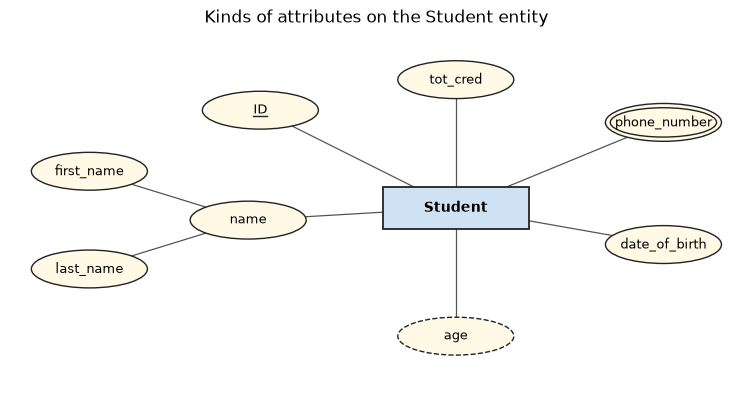

In [2]:
er = ER()
er.entity("Student", 0, 0)
er.attr("Student", "ID", -3.2, 1.6, key=True)                       # key attribute
name = er.attr("Student", "name", -3.4, -0.2)                        # composite attribute ...
er.attr(name, "first_name", -6.0, 0.6, nid="first_name")             # ... with its components
er.attr(name, "last_name", -6.0, -1.0, nid="last_name")
er.attr("Student", "tot_cred", 0, 2.1)                               # simple, single-valued
er.attr("Student", "phone_number", 3.4, 1.4, multi=True)             # multi-valued
er.attr("Student", "date_of_birth", 3.4, -0.6)                       # stored
er.attr("Student", "age", 0, -2.1, derived=True)                     # derived from date_of_birth
er.draw(figsize=(10, 4.6), title="Kinds of attributes on the Student entity")
plt.show()

In [3]:
TODAY = datetime.date(2026, 10, 27)          # fixed "today" so the output is reproducible

# An ENTITY SET in plain Python: a list of entities (dicts). Note the shapes of the attributes.
students = [
    {"ID": "00128", "name": {"first_name": "Wei",   "last_name": "Zhang"},   "tot_cred": 102,
     "phone_number": {"0300-1111111", "042-5555555"}, "date_of_birth": datetime.date(2004, 3, 14)},
    {"ID": "12345", "name": {"first_name": "Ravi",  "last_name": "Shankar"}, "tot_cred": 32,
     "phone_number": {"0301-2222222"},                "date_of_birth": datetime.date(2006, 11, 2)},
    {"ID": "19991", "name": {"first_name": "Lena",  "last_name": "Brandt"},  "tot_cred": 80,
     "phone_number": set(),                           "date_of_birth": datetime.date(2005, 7, 30)},
]

def age(e, today=TODAY):
    """DERIVED attribute: computed on demand, never stored (so it can never be out of date)."""
    dob = e["date_of_birth"]
    return today.year - dob.year - ((today.month, today.day) < (dob.month, dob.day))

for s in students:
    print(f'{s["ID"]}  {s["name"]["first_name"]:<5} {s["name"]["last_name"]:<8} '
          f'phones={len(s["phone_number"])}  age={age(s)}')

# KEY attribute: no two entities may share it
ids = [s["ID"] for s in students]
assert len(ids) == len(set(ids)), "ID must be unique"

00128  Wei   Zhang    phones=2  age=22
12345  Ravi  Shankar  phones=1  age=19
19991  Lena  Brandt   phones=0  age=21


**What just happened?** The composite attribute `name` became a nested dict, the multivalued `phone_number` a *set* (Lena has none — an empty set, which in tables becomes "no rows", not NULL), and `age` is a function, not stored data: a derived attribute stored in a table would silently become wrong on every birthday. The `assert` checks the **key constraint**.

> ⚠️ **Common mistake:** treating a composite attribute as multivalued. `name` has *several parts* but *one value* per student (composite). `phone_number` has *several values* of the same kind (multivalued). They map to tables in completely different ways (section 7).

## 2. Relationships

> 💡 **In plain English:** a relationship links things together (a student takes a section) and says how many of each may be linked: one-to-one, one-to-many or many-to-many.

A **relationship** is an association among entities (*Wei* **takes** *CS-347 section 1*). A **relationship set** (type) `R` among entity sets `E1, …, En` is a subset of `E1 × … × En` — a set of tuples `(e1, …, en)`. Relationships can have their own **descriptive attributes** (`grade` belongs to *takes*, not to the student nor to the section).

### 2.1 Degree

The **degree** of a relationship type = number of participating entity types.

| Degree | Name | Example |
|---|---|---|
| 1 | **unary / recursive** | `Course` *is a prerequisite of* `Course`; `Employee` *supervises* `Employee` |
| 2 | **binary** (by far the most common) | `Student` *takes* `Section` |
| 3 | **ternary** | `Instructor` *guides* `Student` on `Project` (`proj_guide`) |
| n | **n-ary** | rare; usually decomposed or modelled with an associative entity |

In a **recursive** relationship the same entity set plays two different **roles** (e.g. *course* and *prereq*); role names are written on the lines so the meaning is clear.

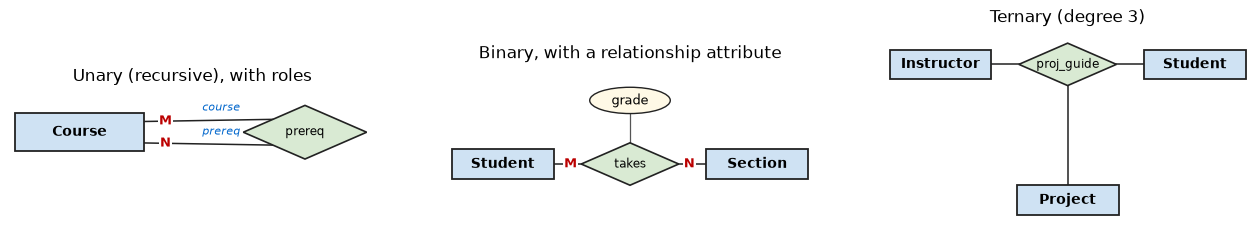

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
# Unary / recursive: two lines between Course and prereq, each with a role name
u = ER(); u.entity("Course", 0, 0); u.rel("prereq", 4.2, 0)
u.link("prereq", "Course", "M", role="course", rel_anchor=(-0.6, 0.24), ent_anchor=(1.2, 0.2))
u.link("prereq", "Course", "N", role="prereq", rel_anchor=(-0.6, -0.24), ent_anchor=(1.2, -0.2))
u.draw(ax=axes[0], title="Unary (recursive), with roles")
# Binary
b = ER(); b.entity("Student", 0, 0); b.entity("Section", 6, 0); b.rel("takes", 3, 0)
b.link("takes", "Student", "M"); b.link("takes", "Section", "N"); b.attr("takes", "grade", 3, 1.5)
b.draw(ax=axes[1], title="Binary, with a relationship attribute")
# Ternary
t = ER(); t.entity("Instructor", 0, 1.6); t.entity("Student", 6, 1.6); t.entity("Project", 3, -1.6)
t.rel("proj_guide", 3, 1.6)
t.link("proj_guide", "Instructor", ""); t.link("proj_guide", "Student", ""); t.link("proj_guide", "Project", "")
t.draw(ax=axes[2], title="Ternary (degree 3)")
plt.show()

### 2.2 Cardinality ratio, participation and (min,max)

**Cardinality ratio** (mapping cardinality) for a binary relationship `R` between `A` and `B` = the **maximum** number of relationship instances an entity can take part in:

| Ratio | Meaning | Example |
|---|---|---|
| **1:1** | an `A` is related to at most one `B` and vice versa | `Department` *chaired by* `Instructor` |
| **1:N** | an `A` relates to many `B`s; each `B` to at most one `A` | `Instructor` *advises* `Student` |
| **N:1** | the mirror image of 1:N | `Student` *advised by* `Instructor` |
| **M:N** | many on both sides | `Student` *takes* `Section` |

**Participation constraint** = the **minimum**: participation of `E` in `R` is **total** (existence dependency, double line) if *every* entity of `E` must take part in at least one relationship instance; otherwise **partial**. Example: every `Instructor` must belong to a `Department` (total), but not every `Instructor` must advise a student (partial).

**(min,max) notation** (Elmasri/Navathe) writes both at once: a pair `(min,max)` on the line next to `E` means *each entity of `E` takes part in at least `min` and at most `max` instances of `R`*; `min = 0` ⇔ partial, `min ≥ 1` ⇔ total; `max = N` means unbounded.

Worked example by hand — `advisor` between `Instructor` and `Student`:

| advisor pair (instructor, student) |
|---|
| (Srinivasan, Shankar) |
| (Katz, Zhang) |
| (Katz, Farooq) |
| (Einstein, Brandt) |

- Each student appears **at most once** (max 1); Chavez appears **0** times → student side `(0,1)`, partial.
- Katz appears **twice** (max 2, i.e. "N"); Crick **0** times → instructor side `(0,N)`, partial.
- Hence the ratio is **1:N** from Instructor to Student.

Below, a function derives all of this from data.

In [5]:
def analyze_relationship(A, B, pairs, name="R"):
    """Given entity sets A, B and a binary relationship instance (set of (a, b) pairs),
    return the cardinality ratio, participation and (min,max) of each side, observed in the data."""
    cnt_a = {a: 0 for a in A}                       # how many relationship instances each a is in
    cnt_b = {b: 0 for b in B}
    for a, b in pairs:
        assert a in cnt_a and b in cnt_b, "relationship must reference existing entities"
        cnt_a[a] += 1
        cnt_b[b] += 1
    min_a, max_a = min(cnt_a.values()), max(cnt_a.values())
    min_b, max_b = min(cnt_b.values()), max(cnt_b.values())
    side_a = "1" if max_a <= 1 else "N"            # many B per A?  -> A side is the "one"
    # ratio A:B is written as (how many A per B) : (how many B per A)
    ratio = f'{"1" if max_b <= 1 else "M"}:{"1" if max_a <= 1 else "N"}'
    ratio = {"M:1": "N:1"}.get(ratio, ratio)       # tidy label
    return {"relationship": name, "ratio A:B": ratio,
            "A participation": "total" if min_a >= 1 else "partial",
            "B participation": "total" if min_b >= 1 else "partial",
            "A (min,max)": (min_a, max_a), "B (min,max)": (min_b, max_b)}

instructors = ["Srinivasan", "Katz", "Einstein", "Crick"]
studs = ["Zhang", "Shankar", "Brandt", "Chavez", "Farooq"]
departments = ["Comp. Sci.", "Physics", "Biology"]
sections = ["CS-101/1/Fall", "CS-101/1/Spring", "CS-347/1/Fall", "PHY-101/1/Fall"]

advisor = {("Srinivasan", "Shankar"), ("Katz", "Zhang"), ("Katz", "Farooq"), ("Einstein", "Brandt")}
chair = {("Comp. Sci.", "Katz"), ("Physics", "Einstein"), ("Biology", "Crick")}
inst_dept = {("Srinivasan", "Comp. Sci."), ("Katz", "Comp. Sci."), ("Einstein", "Physics"), ("Crick", "Biology")}
takes = {("Zhang", "CS-101/1/Fall"), ("Zhang", "CS-347/1/Fall"), ("Shankar", "CS-101/1/Fall"),
         ("Shankar", "CS-101/1/Spring"), ("Brandt", "PHY-101/1/Fall"), ("Farooq", "CS-347/1/Fall")}

rows = [analyze_relationship(instructors, studs, advisor, "advisor (Instructor, Student)"),
        analyze_relationship(departments, instructors, chair, "chair (Department, Instructor)"),
        analyze_relationship(instructors, departments, inst_dept, "inst_dept (Instructor, Department)"),
        analyze_relationship(studs, sections, takes, "takes (Student, Section)")]
result = pd.DataFrame(rows)
print(result.to_string(index=False))
assert list(result["ratio A:B"]) == ["1:N", "1:1", "N:1", "M:N"]

                      relationship ratio A:B A participation B participation A (min,max) B (min,max)
     advisor (Instructor, Student)       1:N         partial         partial      (0, 2)      (0, 1)
    chair (Department, Instructor)       1:1           total         partial      (1, 1)      (0, 1)
inst_dept (Instructor, Department)       N:1           total           total      (1, 1)      (1, 2)
          takes (Student, Section)       M:N         partial           total      (0, 2)      (1, 2)


**What just happened?** The function counts, for every entity, in how many relationship instances it appears. The **maximum** counts give the cardinality ratio, the **minimum** counts give participation. `chair` is 1:1 and total for `Department` (every department has a chair) but partial for `Instructor` (Srinivasan chairs nothing). `inst_dept` is N:1 and total on both sides (every instructor has a department, and in this data every department has an instructor).

**Complexity:** O(|A| + |B| + |R|) time and O(|A| + |B|) space — one pass over the pairs.

> ⚠️ **Common mistake:** concluding a constraint from data. Data can only **refute** a constraint (if Katz advises two students, advisor is certainly *not* 1:1), never prove it: maybe tomorrow a student gets two advisors. Constraints come from the **business rules** (requirements), the data merely has to obey them.

> 🎓 **Exam / interview tip:** the `1`/`N` labels and the `(min,max)` labels are placed on **opposite sides**. For "each department has many instructors, each instructor is in one department": Chen labels → `Department 1 —— N Instructor`; (min,max) → `Department (1,N) —— (1,1) Instructor`, because (min,max) next to an entity describes *that entity's own* participation. Examiners love this.

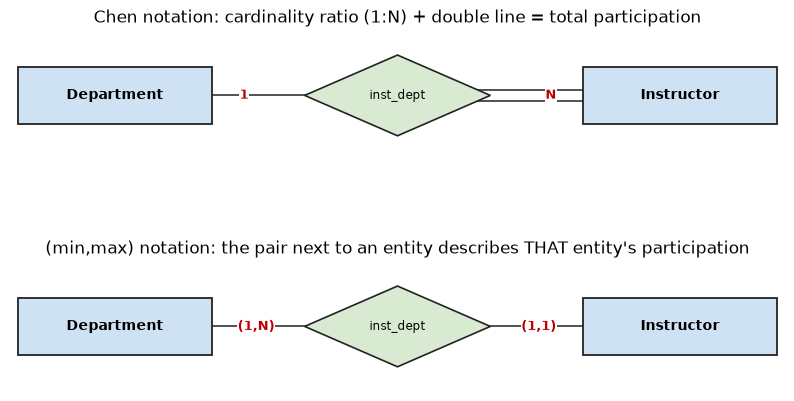

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5))
a = ER(); a.entity("Department", 0, 0); a.entity("Instructor", 7, 0); a.rel("inst_dept", 3.5, 0)
a.link("inst_dept", "Department", "1"); a.link("inst_dept", "Instructor", "N", total=True)
a.draw(ax=axes[0], title="Chen notation: cardinality ratio (1:N) + double line = total participation")
m = ER(); m.entity("Department", 0, 0); m.entity("Instructor", 7, 0); m.rel("inst_dept", 3.5, 0)
m.link("inst_dept", "Department", "(1,N)"); m.link("inst_dept", "Instructor", "(1,1)")
m.draw(ax=axes[1], title="(min,max) notation: the pair next to an entity describes THAT entity's participation")
plt.show()

## 3. Weak Entities and Identifying Relationships

> 💡 **In plain English:** a weak entity cannot be identified on its own, like "flat 3", which only makes sense inside a particular building.

**Analogy:** "Flat 3" is not an address by itself — it only identifies a flat *within a building*. The flat is a weak entity; the building is its owner.

- A **weak entity type** has **no key of its own**; its entities are identified by being related to an entity of another type, the **identifying (owner) entity type**, through an **identifying relationship** (double diamond).
- A weak entity always has **total participation** in the identifying relationship (existence dependency: no building → no flat), and the relationship is 1:N from owner to weak entity (often).
- A weak entity has a **partial key** (**discriminator**, dashed underline) that distinguishes weak entities *of the same owner*. Its full key = owner's key + partial key.

University example: a `Section` is identified by its `Course` + (`sec_id`, `semester`, `year`): "section 1 of CS-101 in Fall 2025". Classic textbook example: `Dependent` of an `Employee`, identified by employee SSN + dependent's name.

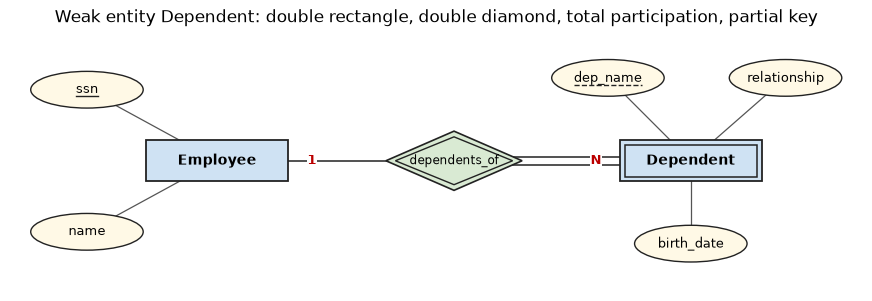

In [7]:
w = ER()
w.entity("Employee", 0, 0); w.entity("Dependent", 8, 0, weak=True)
w.rel("dependents_of", 4, 0, identifying=True)
w.link("dependents_of", "Employee", "1"); w.link("dependents_of", "Dependent", "N", total=True)
w.attr("Employee", "ssn", -2.2, 1.2, key=True); w.attr("Employee", "name", -2.2, -1.2)
w.attr("Dependent", "dep_name", 6.6, 1.4, partial=True)
w.attr("Dependent", "relationship", 9.6, 1.4); w.attr("Dependent", "birth_date", 8, -1.4)
w.draw(figsize=(11, 3.6), title="Weak entity Dependent: double rectangle, double diamond, total participation, partial key")
plt.show()

> ⚠️ **Common mistake:** "a weak entity is any entity with total participation." No — `Instructor` has total participation in `inst_dept` but has its own key (`ID`), so it is a strong entity. *Weak* means **no key of its own**.
>
> 🎓 **Exam tip:** "Could `Section` be made strong?" Yes, by adding a surrogate key such as `section_id` — but then the rule "a section belongs to exactly one course and dies with it" must be enforced by other constraints (FK `NOT NULL` + `ON DELETE CASCADE`). Designers choose weak entities when the identification really is dependent.

## 4. The Complete University ER Diagram

> 💡 **In plain English:** we put all the pieces together into one diagram of a whole university database.

Requirements (simplified Silberschatz *university* schema):

1. The university has **departments** (name, building, budget). Each **instructor** (ID, name, salary) belongs to exactly one department; each **student** (ID, name, total credits) has exactly one major department; each **course** (course_id, title, credits) is offered by exactly one department.
2. A **section** of a course is identified by the course plus section number, semester and year.
3. Instructors **teach** sections (a section may have several instructors); students **take** sections and receive a **grade**.
4. A student may have one instructor as **advisor**; an instructor may advise many students.
5. A course may have other courses as **prerequisites**.

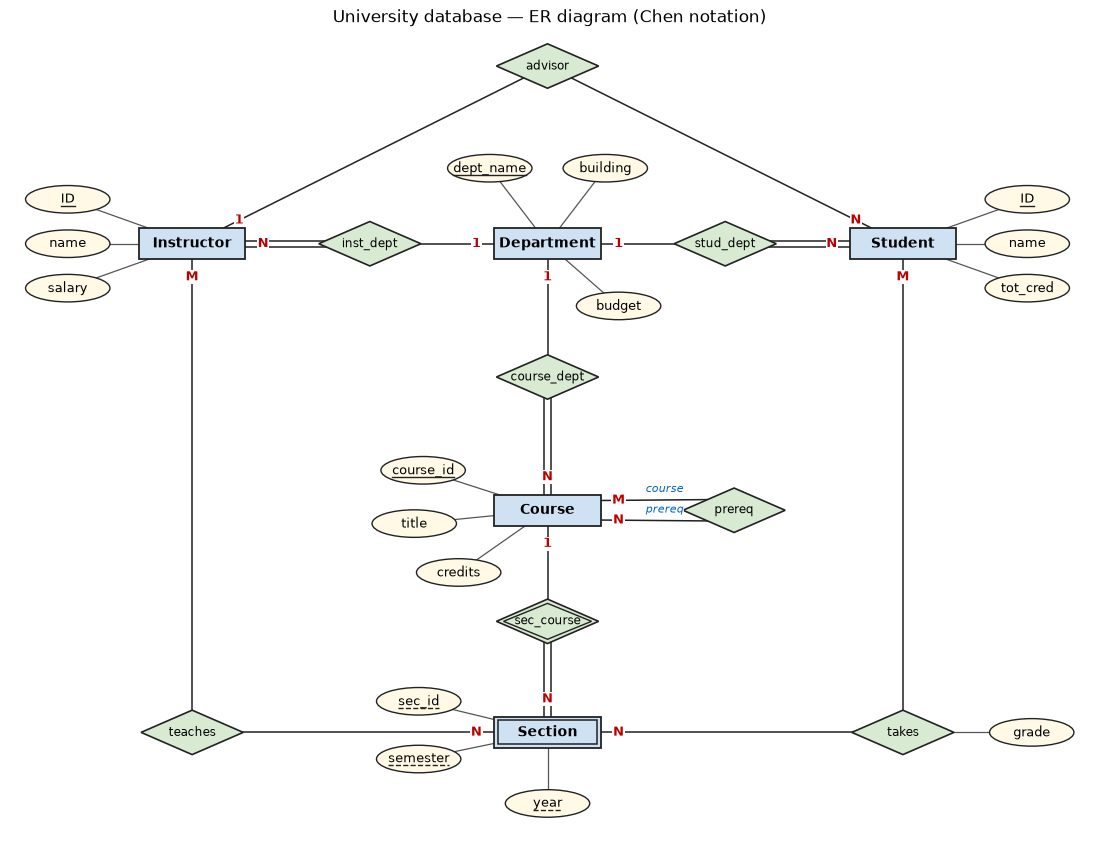

attr      16
rel        8
entity     5


In [8]:
uni = ER()
# entity sets
uni.entity("Instructor", -8, 2); uni.entity("Department", 0, 2); uni.entity("Student", 8, 2)
uni.entity("Course", 0, -4); uni.entity("Section", 0, -9, weak=True)
# attributes
uni.attr("Instructor", "ID", -10.8, 3.0, key=True); uni.attr("Instructor", "name", -10.8, 2.0)
uni.attr("Instructor", "salary", -10.8, 1.0)
uni.attr("Department", "dept_name", -1.3, 3.7, key=True); uni.attr("Department", "building", 1.3, 3.7)
uni.attr("Department", "budget", 1.6, 0.6)
uni.attr("Student", "ID", 10.8, 3.0, key=True); uni.attr("Student", "name", 10.8, 2.0)
uni.attr("Student", "tot_cred", 10.8, 1.0)
uni.attr("Course", "course_id", -2.8, -3.1, key=True); uni.attr("Course", "title", -3.0, -4.3)
uni.attr("Course", "credits", -2.0, -5.4)
uni.attr("Section", "sec_id", -2.9, -8.3, partial=True); uni.attr("Section", "semester", -2.9, -9.6, partial=True)
uni.attr("Section", "year", 0, -10.6, partial=True)
# relationship sets with cardinality and participation
uni.rel("advisor", 0, 6.0); uni.link("advisor", "Instructor", "1"); uni.link("advisor", "Student", "N")
uni.rel("inst_dept", -4, 2); uni.link("inst_dept", "Department", "1"); uni.link("inst_dept", "Instructor", "N", total=True)
uni.rel("stud_dept", 4, 2); uni.link("stud_dept", "Department", "1"); uni.link("stud_dept", "Student", "N", total=True)
uni.rel("course_dept", 0, -1); uni.link("course_dept", "Department", "1"); uni.link("course_dept", "Course", "N", total=True)
uni.rel("sec_course", 0, -6.5, identifying=True)
uni.link("sec_course", "Course", "1"); uni.link("sec_course", "Section", "N", total=True)
uni.rel("teaches", -8, -9); uni.link("teaches", "Instructor", "M"); uni.link("teaches", "Section", "N")
uni.rel("takes", 8, -9); uni.link("takes", "Student", "M"); uni.link("takes", "Section", "N")
uni.attr("takes", "grade", 10.9, -9.0)
uni.rel("prereq", 4.2, -4)                                    # recursive, with role names
uni.link("prereq", "Course", "M", role="course", rel_anchor=(-0.6, 0.24), ent_anchor=(1.2, 0.22))
uni.link("prereq", "Course", "N", role="prereq", rel_anchor=(-0.6, -0.24), ent_anchor=(1.2, -0.22))
uni.draw(figsize=(14, 10.5), title="University database — ER diagram (Chen notation)")
plt.show()

kinds = pd.Series({n: d["kind"] for n, d in uni.G.nodes(data=True)}).value_counts()
print(kinds.to_string())

**What just happened?** The whole design fits on one page: 5 entity sets (one weak), 8 relationship sets (one identifying, one recursive), and 16 attributes (one of them, `grade`, on a relationship). Reading it aloud is the best check: *"Each Instructor belongs to exactly one Department (double line + N), a Department has many Instructors"*, *"a Section cannot exist without its Course"*, *"Students take many Sections, Sections have many Students, each enrolment has a grade."*

> ⚠️ **Common mistake:** putting `dept_name` as an attribute of `Instructor` **and** drawing `inst_dept`. In an ER diagram the relationship already says it; the foreign key appears only when we *map* to tables. Redundant attributes like that are a classic exam deduction.

## 5. Enhanced ER (EER)

> 💡 **In plain English:** enhanced ER handles "kinds of" things: a person can be a student, an employee or both, and each kind inherits the person's details.

Plain ER struggles with "kinds of" things: every student and every employee is a person; a TA is both a student and an employee. The **Enhanced (Extended) ER model** adds:

- **Subclass / superclass**: `Student` is a subclass of `Person` (an *IS-A* relationship). A subclass entity is the *same* real-world entity as its superclass entity, seen in a more specific role.
- **Attribute and relationship inheritance**: a subclass inherits all attributes and relationships of its superclass and can add its own (`Student` inherits `name`, adds `gpa`).
- **Specialization** (top-down): define subclasses of a superclass by distinguishing characteristics. **Generalization** (bottom-up): find the common features of several entity types (`Car`, `Truck`) and build a superclass (`Vehicle`). Same diagram, different design process.
- Two independent **constraints** on a specialization:

| | **Disjoint** (`d`): an entity is in at most one subclass | **Overlapping** (`o`): may be in several |
|---|---|---|
| **Total** (double line): every superclass entity must be in some subclass | `Account` → {`Savings`, `Checking`} | `Person` → {`Student`, `Employee`} if everyone is at least one |
| **Partial** (single line): may be in none | `Employee` → {`Secretary`, `Engineer`, `Technician`} | `Person` → {`Student`, `Employee`} where alumni are neither |

- **Predicate-defined** (attribute-defined) subclasses: membership decided by a condition on an attribute, e.g. `job_type = 'Engineer'`; **user-defined** otherwise.
- **Specialization hierarchy** (each subclass has one superclass) vs. **lattice** (a *shared subclass* such as `TA` has several superclasses → **multiple inheritance**).
- **Category / union type** (`∪` circle): a subclass of the **union** of *different* superclasses. `Owner` of a vehicle is a `Person` **or** a `Bank` **or** a `Company`. An owner entity inherits from *only one* of them (selective inheritance) — unlike a shared subclass, which belongs to *all* its superclasses.
- **Aggregation** (Silberschatz): treat a relationship set and its entities as a **higher-level entity** so it can take part in another relationship: a `Manager` *monitors* the (Employee *works_on* Project) assignment.

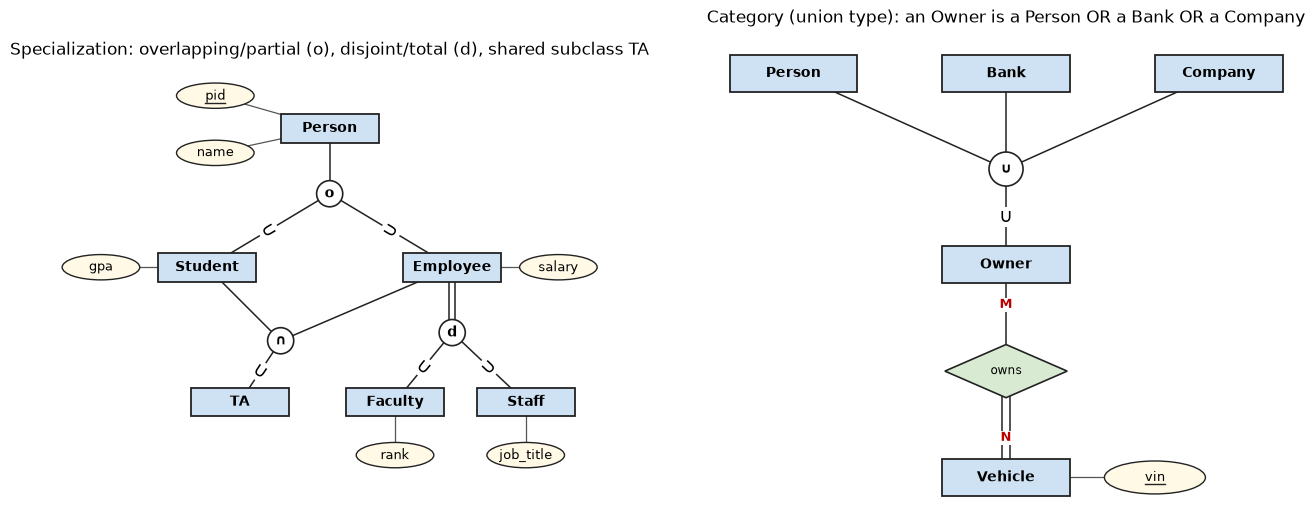

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
# --- Specialization hierarchy / lattice
s = ER()
s.entity("Person", 0, 4); s.attr("Person", "pid", -2.8, 4.8, key=True); s.attr("Person", "name", -2.8, 3.4)
s.circle("o1", 0, 2.4, "o")                                  # overlapping
s.isa("o1", "Person", total=False)                           # partial: a Person may be neither
s.entity("Student", -3, 0.6); s.entity("Employee", 3, 0.6)
s.isa("o1", "Student", subset=True); s.isa("o1", "Employee", subset=True)
s.attr("Student", "gpa", -5.6, 0.6); s.attr("Employee", "salary", 5.6, 0.6)
s.circle("d1", 3, -1.0, "d")                                 # disjoint
s.isa("d1", "Employee", total=True)                          # total: every employee is faculty or staff
s.entity("Faculty", 1.6, -2.7); s.entity("Staff", 4.8, -2.7)
s.isa("d1", "Faculty", subset=True); s.isa("d1", "Staff", subset=True)
s.attr("Faculty", "rank", 1.6, -4.0); s.attr("Staff", "job_title", 4.8, -4.0)
s.entity("TA", -2.2, -2.7)                                   # shared subclass -> lattice
s.circle("ta", -1.2, -1.2, "∩")
s.isa("ta", "Student"); s.isa("ta", "Employee"); s.isa("ta", "TA", subset=True)
s.draw(ax=axes[0], title="Specialization: overlapping/partial (o), disjoint/total (d), shared subclass TA")
# --- Category (union type)
c = ER()
c.entity("Person", -4, 3); c.entity("Bank", 0, 3); c.entity("Company", 4, 3)
c.circle("u", 0, 1.2, "∪")
for e in ["Person", "Bank", "Company"]:
    c.isa("u", e)
c.entity("Owner", 0, -0.6); c.isa("u", "Owner", subset=True)    # partial category (single line)
c.rel("owns", 0, -2.6); c.entity("Vehicle", 0, -4.6)
c.link("owns", "Owner", "M"); c.link("owns", "Vehicle", "N", total=True)
c.attr("Vehicle", "vin", 2.8, -4.6, key=True)
c.draw(ax=axes[1], title="Category (union type): an Owner is a Person OR a Bank OR a Company")
plt.show()

Reading the left diagram: *a Person may be a Student, an Employee, both, or neither* (`o`, single line); *every Employee is exactly one of Faculty or Staff* (`d`, double line); `TA` is a **shared subclass** of both `Student` and `Employee` (an intersection, drawn here with `∩`; textbooks often just draw two lines into `TA`) and inherits from both. The `∪` marks on the lines point the opening towards the superclass. On the right, `Owner` is a **category**: each owner is *one of* the three superclasses.

Now **aggregation**:

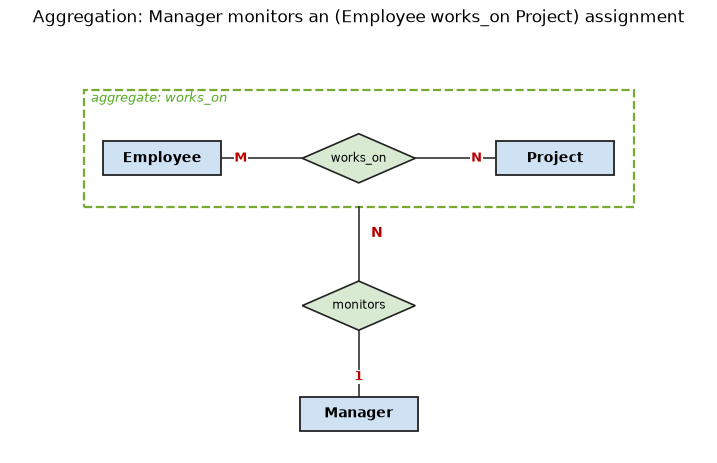

In [10]:
g = ER()
g.entity("Employee", -4, 0); g.entity("Project", 4, 0); g.rel("works_on", 0, 0)
g.link("works_on", "Employee", "M"); g.link("works_on", "Project", "N")
g.aggregate(-5.6, -1.0, 5.6, 1.4, label="aggregate: works_on")
g.rel("monitors", 0, -3.0); g.entity("Manager", 0, -5.2)
g.link("monitors", "Manager", "1", ent_anchor=(0, 0.35))
g.draw(figsize=(9, 6), title="Aggregation: Manager monitors an (Employee works_on Project) assignment")
g_ax = plt.gca()
g_ax.plot([0, 0], [-1.0, -2.5], color="#222", lw=1.1)       # line from the aggregate box to 'monitors'
g_ax.text(0.25, -1.6, "N", color="#b00", fontweight="bold")
plt.show()

**Why aggregation?** ER does not allow a relationship *between relationships*. Without aggregation you would draw a ternary `monitors(Employee, Project, Manager)` — but then a manager could monitor an (employee, project) pair that is **not** an actual `works_on` assignment, and the redundancy is hard to control. Aggregation says: "the thing being monitored is a `works_on` *instance*". When mapped to tables, `monitors` gets the primary key of `works_on` (employee, project) plus the manager's key, with a foreign key to `works_on`.

> 🎓 **Exam tip:** "shared subclass vs. category" — a shared subclass (`TA`) is in the **intersection** of its superclasses and inherits from **all** of them; a category (`Owner`) is a subset of the **union** and each member inherits from **exactly one**.

## 6. Minimization of ER Diagrams (minimum number of tables)

> 💡 **In plain English:** a common exam question asks for the fewest tables a diagram needs; the answer depends on the one-to-one, one-to-many and many-to-many rules.

A favourite GATE/university question: *"What is the minimum number of tables needed to represent this ER diagram?"* The idea: start with one table per entity set and per relationship set, then **merge** a relationship table into an entity table whenever the merge creates no redundancy and never forces a NULL into a primary key.

Rules for a binary relationship `R` between strong entity sets `E1` and `E2` (GeeksforGeeks' convention: NULLs are allowed in non-key columns but never in the primary key):

| Cardinality | Participation | Min. tables | How |
|---|---|---|---|
| **M:N** | any | **3** | `R(key1, key2)` cannot merge: either side would repeat |
| **1:N** | any | **2** | merge `R` into the **N side** (FK column) |
| **1:1** | partial on both sides | **2** | merge `R` into either side (nullable, `UNIQUE` FK) |
| **1:1** | total on **at least one** side | **1** | merge all three into one table, keyed by the key of a side that must always be present (the partial side's key if the other side is total) |

Extra tables: **+1 per multivalued attribute**; a **weak entity** absorbs its identifying relationship (no separate table for the relationship).

In [11]:
def min_tables(card, total_e1=False, total_e2=False):
    """Minimum number of tables for E1 --R-- E2 (strong entities, binary R). card in {'1:1','1:N','N:1','M:N'}."""
    if card == "M:N":
        return 3                    # E1, E2, R(k1, k2)
    if card in ("1:N", "N:1"):
        return 2                    # R merged into the many side
    if card == "1:1":
        return 1 if (total_e1 or total_e2) else 2
    raise ValueError(card)

cases = [("M:N", False, False), ("1:N", True, False), ("N:1", False, True),
         ("1:1", False, False), ("1:1", True, False), ("1:1", True, True)]
print(pd.DataFrame([(c, t1, t2, min_tables(c, t1, t2)) for c, t1, t2 in cases],
                   columns=["cardinality", "E1 total?", "E2 total?", "min tables"]).to_string(index=False))

cardinality  E1 total?  E2 total?  min tables
        M:N      False      False           3
        1:N       True      False           2
        N:1      False       True           2
        1:1      False      False           2
        1:1       True      False           1
        1:1       True       True           1


Let us **prove** two rows with real tables: merging an **M:N** relationship into an entity table repeats data (so 3 tables are needed), while merging a **1:N** relationship into the N side does not.

In [12]:
z = sqlite3.connect(":memory:")
z.executescript("""
CREATE TABLE student(sid TEXT PRIMARY KEY, name TEXT, tot_cred INT);
CREATE TABLE course(cid TEXT PRIMARY KEY, title TEXT);
CREATE TABLE enroll(sid TEXT REFERENCES student, cid TEXT REFERENCES course, PRIMARY KEY(sid, cid));
INSERT INTO student VALUES ('S1','Zhang',102),('S2','Shankar',32);
INSERT INTO course VALUES ('C1','Intro CS'),('C2','Databases');
INSERT INTO enroll VALUES ('S1','C1'),('S1','C2'),('S2','C1');
""")
# Try to merge the M:N relationship into Student: one row per (student, course) -> student data repeats
merged = show(z, "SELECT s.sid, s.name, s.tot_cred, e.cid FROM student s JOIN enroll e USING(sid)")
print("M:N merged into Student:\n", merged)
print("sid is no longer a key (repeats):", merged.sid.duplicated().any(),
      "-> name/tot_cred stored", int(merged.sid.duplicated().sum()), "extra time(s)")

# 1:N advisor: each student has at most one advisor -> merge into Student as a column
z.executescript("""
CREATE TABLE instructor(iid TEXT PRIMARY KEY, name TEXT);
INSERT INTO instructor VALUES ('I1','Katz'),('I2','Srinivasan');
ALTER TABLE student ADD COLUMN advisor_iid TEXT REFERENCES instructor(iid);  -- the merged relationship
UPDATE student SET advisor_iid='I1' WHERE sid='S1';
""")
s = show(z, "SELECT * FROM student")
print("\n1:N advisor merged into Student (N side):\n", s)
assert not s.sid.duplicated().any()                       # still one row per student: no redundancy

M:N merged into Student:
   sid     name  tot_cred cid
0  S1    Zhang       102  C1
1  S1    Zhang       102  C2
2  S2  Shankar        32  C1
sid is no longer a key (repeats): True -> name/tot_cred stored 1 extra time(s)

1:N advisor merged into Student (N side):
   sid     name  tot_cred advisor_iid
0  S1    Zhang       102          I1
1  S2  Shankar        32        None


In [13]:
# 1:1 with total participation on ONE side -> 1 table (Person partial, Passport total)
z.executescript("""
CREATE TABLE person_passport(
    person_id   TEXT PRIMARY KEY,         -- key of the PARTIAL side: always present
    name        TEXT NOT NULL,
    passport_no TEXT UNIQUE,              -- the total side's key: NULL when a person has no passport
    issued      TEXT
);
INSERT INTO person_passport VALUES ('P1','Ali','AB123','2024-05-01'),
                                   ('P2','Sara',NULL,NULL),            -- no passport: allowed
                                   ('P3','Omar','CD456','2025-01-10');
""")
print(show(z, "SELECT * FROM person_passport"))
try:   # a passport cannot belong to two people: UNIQUE enforces the '1' on the person side
    z.execute("INSERT INTO person_passport VALUES ('P4','Hina','AB123','2026-01-01')")
except sqlite3.IntegrityError as e:
    print("Rejected duplicate passport ->", e)

  person_id  name passport_no      issued
0        P1   Ali       AB123  2024-05-01
1        P2  Sara        None        None
2        P3  Omar       CD456  2025-01-10
Rejected duplicate passport -> UNIQUE constraint failed: person_passport.passport_no


**What just happened?** Merging the M:N `enroll` into `student` made `sid` repeat, so Zhang's name and credits were stored twice — redundancy, and `sid` stopped being a key; hence M:N needs its own table (3 in total). The 1:N `advisor` merged into the N side as a single nullable column — still one row per student (2 tables). For 1:1 with Passport's participation total, one table keyed by `person_id` holds everything: people without passports simply have NULLs, and `UNIQUE(passport_no)` keeps it 1:1.

**Example question:** *E1 —(M:N)— R1 — E2 —(1:N)— R2 — E3, with E2 having one multivalued attribute.* Tables: E1, E2, E3, R1 (M:N) = 4; R2 merges into the N side; +1 for the multivalued attribute → **5**.

## 7. ER → Relational Mapping, Rule by Rule

> 💡 **In plain English:** a step-by-step recipe turns each part of the diagram into real tables, and the rules become constraints the database enforces.

The standard algorithm (Elmasri/Navathe ch. 9, 7 steps + 2 for EER). `PK` = primary key, `FK` = foreign key.

| Step | ER construct | Relational result |
|---|---|---|
| 1 | **Strong entity** `E` | table `E` with all *simple* attributes; composite → its components; derived → omitted; PK = key |
| 2 | **Weak entity** `W` with owner `E` | table `W` with its attributes + FK to `E`'s PK; PK = owner PK + partial key; usually `ON DELETE CASCADE` |
| 3 | **1:1** relationship | *FK approach*: FK in one side (prefer the side with **total** participation), `UNIQUE`; or *merged relation* (both total); or *cross-reference* table |
| 4 | **1:N** relationship | FK in the **N side** table (+ relationship attributes there) |
| 5 | **M:N** relationship | new table `R(PK_A, PK_B, attrs)`; PK = (PK_A, PK_B); both FKs |
| 6 | **Multivalued attribute** `A` of `E` | new table `E_A(PK_E, A)`; PK = both columns |
| 7 | **n-ary** relationship | new table with FKs to all participants; PK = combination of FKs (minus those of entities on a "1" side) |
| 8 | **Specialization** | options **A–D** (section 8) |
| 9 | **Category (union)** | surrogate key in the category table, referenced from each superclass |

Now we map the university diagram into SQLite, with `PRAGMA foreign_keys = ON` (SQLite leaves foreign keys **off** by default for backwards compatibility — a classic gotcha).

In [14]:
U = sqlite3.connect(":memory:")
U.execute("PRAGMA foreign_keys = ON")              # enforce FKs in SQLite
U.executescript("""
-- STEP 1: strong entities ---------------------------------------------------------------
CREATE TABLE department(
    dept_name  TEXT PRIMARY KEY,
    building   TEXT NOT NULL,
    budget     REAL CHECK (budget > 0),
    chair_id   TEXT UNIQUE                     -- STEP 3 (1:1 chair): FK + UNIQUE; added below
               REFERENCES instructor(ID) ON DELETE SET NULL
);
CREATE TABLE instructor(
    ID         TEXT PRIMARY KEY,
    name       TEXT NOT NULL,
    salary     REAL CHECK (salary > 29000),
    dept_name  TEXT NOT NULL                   -- STEP 4 (1:N inst_dept), NOT NULL = total participation
               REFERENCES department(dept_name) ON DELETE RESTRICT
);
CREATE TABLE student(
    ID          TEXT PRIMARY KEY,
    first_name  TEXT NOT NULL,                 -- composite attribute 'name' flattened
    last_name   TEXT NOT NULL,
    date_of_birth TEXT,                        -- derived 'age' is NOT stored
    tot_cred    INT  CHECK (tot_cred >= 0),
    dept_name   TEXT NOT NULL REFERENCES department(dept_name),   -- STEP 4 stud_dept (total)
    advisor_id  TEXT REFERENCES instructor(ID) ON DELETE SET NULL -- STEP 4 advisor (partial -> nullable)
);
CREATE TABLE course(
    course_id  TEXT PRIMARY KEY,
    title      TEXT NOT NULL,
    credits    INT CHECK (credits BETWEEN 1 AND 6),
    dept_name  TEXT NOT NULL REFERENCES department(dept_name)     -- STEP 4 course_dept
);
-- STEP 2: weak entity Section (owner Course); identifying relationship absorbed ---------
CREATE TABLE section(
    course_id  TEXT REFERENCES course(course_id) ON DELETE CASCADE,
    sec_id     TEXT,
    semester   TEXT CHECK (semester IN ('Fall','Winter','Spring','Summer')),
    year       INT  CHECK (year BETWEEN 1990 AND 2100),
    room       TEXT,
    PRIMARY KEY (course_id, sec_id, semester, year)               -- owner key + partial key
);
-- STEP 5: M:N relationships -------------------------------------------------------------
CREATE TABLE teaches(
    ID TEXT REFERENCES instructor(ID) ON DELETE CASCADE,
    course_id TEXT, sec_id TEXT, semester TEXT, year INT,
    PRIMARY KEY (ID, course_id, sec_id, semester, year),
    FOREIGN KEY (course_id, sec_id, semester, year) REFERENCES section ON DELETE CASCADE
);
CREATE TABLE takes(
    ID TEXT REFERENCES student(ID) ON DELETE CASCADE,
    course_id TEXT, sec_id TEXT, semester TEXT, year INT,
    grade TEXT CHECK (grade IN ('A','A-','B+','B','B-','C+','C','C-','D','F') OR grade IS NULL),
    PRIMARY KEY (ID, course_id, sec_id, semester, year),
    FOREIGN KEY (course_id, sec_id, semester, year) REFERENCES section ON DELETE CASCADE
);
CREATE TABLE prereq(                                              -- recursive M:N with roles
    course_id  TEXT REFERENCES course(course_id) ON DELETE CASCADE,
    prereq_id  TEXT REFERENCES course(course_id) ON DELETE CASCADE,
    PRIMARY KEY (course_id, prereq_id),
    CHECK (course_id <> prereq_id)
);
-- STEP 6: multivalued attribute phone_number --------------------------------------------
CREATE TABLE student_phone(
    ID TEXT REFERENCES student(ID) ON DELETE CASCADE,
    phone_number TEXT,
    PRIMARY KEY (ID, phone_number)
);
-- STEP 7: ternary relationship proj_guide(instructor, student, project) -------------------
CREATE TABLE project(project_id TEXT PRIMARY KEY, title TEXT);
CREATE TABLE proj_guide(
    instructor_id TEXT REFERENCES instructor(ID),
    student_id    TEXT REFERENCES student(ID),
    project_id    TEXT REFERENCES project(project_id),
    PRIMARY KEY (instructor_id, student_id, project_id)
);
""")
print(show(U, "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name").name.tolist())

['course', 'department', 'instructor', 'prereq', 'proj_guide', 'project', 'section', 'student', 'student_phone', 'takes', 'teaches']


In [15]:
U.executescript("""
INSERT INTO department(dept_name, building, budget) VALUES
  ('Comp. Sci.','Taylor',100000), ('Physics','Watson',70000), ('Biology','Watson',90000);
INSERT INTO instructor VALUES
  ('10101','Srinivasan',65000,'Comp. Sci.'), ('45565','Katz',75000,'Comp. Sci.'),
  ('22222','Einstein',95000,'Physics'),     ('76766','Crick',72000,'Biology');
UPDATE department SET chair_id='45565' WHERE dept_name='Comp. Sci.';
UPDATE department SET chair_id='22222' WHERE dept_name='Physics';
UPDATE department SET chair_id='76766' WHERE dept_name='Biology';
INSERT INTO student VALUES
  ('00128','Wei','Zhang','2004-03-14',102,'Comp. Sci.','45565'),
  ('12345','Ravi','Shankar','2006-11-02',32,'Comp. Sci.','10101'),
  ('19991','Lena','Brandt','2005-07-30',80,'Physics','22222'),
  ('23121','Maria','Chavez','2003-01-21',110,'Biology',NULL),
  ('44553','Omar','Farooq','2005-09-09',56,'Comp. Sci.','45565');
INSERT INTO student_phone VALUES ('00128','0300-1111111'),('00128','042-5555555'),('12345','0301-2222222');
INSERT INTO course VALUES
  ('CS-101','Intro. to Computer Science',4,'Comp. Sci.'), ('CS-347','Database System Concepts',3,'Comp. Sci.'),
  ('CS-190','Game Design',4,'Comp. Sci.'), ('PHY-101','Physical Principles',4,'Physics'),
  ('BIO-101','Intro. to Biology',4,'Biology');
INSERT INTO prereq VALUES ('CS-347','CS-101'), ('CS-190','CS-101');
INSERT INTO section VALUES
  ('CS-101','1','Fall',2025,'Taylor 3128'), ('CS-101','1','Spring',2026,'Taylor 3128'),
  ('CS-347','1','Fall',2025,'Taylor 3128'), ('PHY-101','1','Fall',2025,'Watson 100'),
  ('BIO-101','1','Spring',2026,'Watson 120');
INSERT INTO teaches VALUES
  ('10101','CS-101','1','Fall',2025), ('45565','CS-101','1','Spring',2026), ('10101','CS-347','1','Fall',2025),
  ('22222','PHY-101','1','Fall',2025), ('76766','BIO-101','1','Spring',2026);
INSERT INTO takes VALUES
  ('00128','CS-101','1','Fall',2025,'A'), ('00128','CS-347','1','Fall',2025,'A-'),
  ('12345','CS-101','1','Fall',2025,'C'), ('12345','CS-101','1','Spring',2026,NULL),
  ('19991','PHY-101','1','Fall',2025,'B'), ('44553','CS-347','1','Fall',2025,'B+'),
  ('23121','BIO-101','1','Spring',2026,NULL);
INSERT INTO project VALUES ('P1','Learned index structures');
INSERT INTO proj_guide VALUES ('45565','00128','P1'), ('10101','00128','P1');
""")
print(show(U, """SELECT s.first_name || ' ' || s.last_name AS student, s.dept_name,
                        i.name AS advisor, COUNT(t.course_id) AS sections_taken
                 FROM student s LEFT JOIN instructor i ON s.advisor_id = i.ID
                                LEFT JOIN takes t ON t.ID = s.ID
                 GROUP BY s.ID ORDER BY s.ID"""))
print(show(U, "SELECT d.dept_name, i.name AS chair FROM department d JOIN instructor i ON d.chair_id = i.ID"))

        student   dept_name     advisor  sections_taken
0     Wei Zhang  Comp. Sci.        Katz               2
1  Ravi Shankar  Comp. Sci.  Srinivasan               2
2   Lena Brandt     Physics    Einstein               1
3  Maria Chavez     Biology        None               1
4   Omar Farooq  Comp. Sci.        Katz               1
    dept_name     chair
0  Comp. Sci.      Katz
1     Physics  Einstein
2     Biology     Crick


Now let the constraints **work**: each rejected statement below is the diagram's meaning, enforced by the DBMS.

In [16]:
tests = {
    "1:1 chair: Katz cannot chair a 2nd dept":
        "UPDATE department SET chair_id='45565' WHERE dept_name='Physics'",
    "total participation: instructor needs a dept":
        "INSERT INTO instructor VALUES ('99999','Nobody',50000,NULL)",
    "referential integrity: unknown department":
        "INSERT INTO student VALUES ('55555','A','B','2005-01-01',0,'History',NULL)",
    "weak entity: section of a non-existent course":
        "INSERT INTO section VALUES ('CS-999','1','Fall',2025,'X')",
    "M:N key: same student, same section twice":
        "INSERT INTO takes VALUES ('00128','CS-101','1','Fall',2025,'B')",
    "multivalued: duplicate phone for same student":
        "INSERT INTO student_phone VALUES ('00128','0300-1111111')",
    "domain (CHECK): invalid grade":
        "INSERT INTO takes VALUES ('19991','CS-101','1','Fall',2025,'Z')",
    "recursive: course cannot be its own prereq":
        "INSERT INTO prereq VALUES ('CS-101','CS-101')",
}
for label, sql in tests.items():
    try:
        U.execute(sql)
        print(f"ACCEPTED (unexpected!)  {label}")
    except sqlite3.IntegrityError as e:
        print(f"rejected ✔ {label:47} -> {e}")

rejected ✔ 1:1 chair: Katz cannot chair a 2nd dept         -> UNIQUE constraint failed: department.chair_id
rejected ✔ total participation: instructor needs a dept    -> NOT NULL constraint failed: instructor.dept_name
rejected ✔ referential integrity: unknown department       -> FOREIGN KEY constraint failed
rejected ✔ weak entity: section of a non-existent course   -> FOREIGN KEY constraint failed
rejected ✔ M:N key: same student, same section twice       -> UNIQUE constraint failed: takes.ID, takes.course_id, takes.sec_id, takes.semester, takes.year
rejected ✔ multivalued: duplicate phone for same student   -> UNIQUE constraint failed: student_phone.ID, student_phone.phone_number
rejected ✔ domain (CHECK): invalid grade                   -> CHECK constraint failed: grade IN ('A','A-','B+','B','B-','C+','C','C-','D','F') OR grade IS NULL
rejected ✔ recursive: course cannot be its own prereq      -> CHECK constraint failed: course_id <> prereq_id


In [17]:
# Weak-entity existence dependency: deleting a course cascades to its sections, and from there to takes/teaches
count = lambda t: U.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
before = {t: count(t) for t in ["course", "section", "takes", "teaches"]}
U.execute("DELETE FROM course WHERE course_id = 'BIO-101'")
after = {t: count(t) for t in ["course", "section", "takes", "teaches"]}
print(pd.DataFrame([before, after], index=["before", "after"]))
assert (before["section"] - after["section"], before["takes"] - after["takes"]) == (1, 1)

# ON DELETE SET NULL: removing an advisor keeps the student but clears the link (partial participation)
U.execute("DELETE FROM proj_guide WHERE instructor_id = '10101'")   # proj_guide has no ON DELETE action
U.execute("DELETE FROM instructor WHERE ID = '10101'")             # teaches rows cascade, advisor -> NULL
print(show(U, "SELECT ID, last_name, advisor_id FROM student WHERE ID = '12345'"))

        course  section  takes  teaches
before       5        5      7        5
after        4        4      6        4
      ID last_name advisor_id
0  12345   Shankar       None


**What just happened?** Every line of the ER diagram became a constraint:

- **1:1** `chair` → `chair_id UNIQUE` (Katz could not chair two departments).
- **Total participation** → `NOT NULL` FK (an instructor with no department was rejected). **Partial** → nullable FK (`advisor_id`).
- **Weak entity** → composite PK containing the owner's key + `ON DELETE CASCADE`: deleting `BIO-101` also removed its section and the enrolment in it.
- **M:N** → a separate table whose PK is the combination of both keys (no duplicate enrolment).
- **Multivalued attribute** → its own table, PK (ID, phone_number).
- Deleting Srinivasan set Shankar's `advisor_id` to NULL instead of deleting the student (`ON DELETE SET NULL`).

> ⚠️ **Common mistake:** in SQLite a `REFERENCES` clause does nothing unless `PRAGMA foreign_keys = ON` is executed on **every connection**. PostgreSQL, MySQL (InnoDB), SQL Server and Oracle always enforce them.

## 8. Mapping Specialization: Options A–D

> 💡 **In plain English:** there are four ways to store "kinds of" things in tables, and only some of them can store a person who is both a student and an employee, or neither.

Superclass `Person(pid, name)` with subclasses `Student(gpa)` and `Employee(salary)`. Our test data deliberately includes every case: Ali (student only), Sara (employee only), Tariq (**both** → overlapping) and Nadia (**neither** → partial).

| Option | Tables | Works for | Drawback |
|---|---|---|---|
| **8A** multiple relations, superclass + subclasses | `Person(pid, name)`, `Student(pid, gpa)`, `Employee(pid, salary)` | **any** specialization | joins needed to get the full picture |
| **8B** multiple relations, subclasses only | `Student(pid, name, gpa)`, `Employee(pid, name, salary)` | only **total + disjoint** | entities in no subclass are lost; overlapping ones duplicated |
| **8C** single relation with one type attribute | `Person(pid, name, type, gpa, salary)` | only **disjoint** | many NULLs |
| **8D** single relation with several Boolean type flags | `Person(pid, name, is_student, gpa, is_employee, salary)` | **overlapping** too (and disjoint) | many NULLs, wide table |

In [18]:
people = [("p1", "Ali", 3.4, None), ("p2", "Sara", None, 90000), ("p3", "Tariq", 3.1, 40000), ("p4", "Nadia", None, None)]
S = sqlite3.connect(":memory:")
S.execute("PRAGMA foreign_keys = ON")

# ---- 8A: superclass + one table per subclass (shares the key)
S.executescript("""
CREATE TABLE a_person(pid TEXT PRIMARY KEY, name TEXT NOT NULL);
CREATE TABLE a_student(pid TEXT PRIMARY KEY REFERENCES a_person ON DELETE CASCADE, gpa REAL);
CREATE TABLE a_employee(pid TEXT PRIMARY KEY REFERENCES a_person ON DELETE CASCADE, salary REAL);
""")
for pid, name, gpa, sal in people:
    S.execute("INSERT INTO a_person VALUES (?,?)", (pid, name))
    if gpa is not None: S.execute("INSERT INTO a_student VALUES (?,?)", (pid, gpa))
    if sal is not None: S.execute("INSERT INTO a_employee VALUES (?,?)", (pid, sal))

# ---- 8B: only subclass tables (superclass attributes copied into each)
S.executescript("""
CREATE TABLE b_student(pid TEXT PRIMARY KEY, name TEXT, gpa REAL);
CREATE TABLE b_employee(pid TEXT PRIMARY KEY, name TEXT, salary REAL);
""")
for pid, name, gpa, sal in people:
    if gpa is not None: S.execute("INSERT INTO b_student VALUES (?,?,?)", (pid, name, gpa))
    if sal is not None: S.execute("INSERT INTO b_employee VALUES (?,?,?)", (pid, name, sal))

# ---- 8C: single table with ONE type attribute (disjoint only)
S.execute("""CREATE TABLE c_person(pid TEXT PRIMARY KEY, name TEXT, ptype TEXT CHECK (ptype IN ('student','employee')),
             gpa REAL, salary REAL)""")
c_failed = []
for pid, name, gpa, sal in people:
    if gpa is not None and sal is not None:
        c_failed.append(name)                         # cannot be both with one type value
        continue
    ptype = "student" if gpa is not None else "employee" if sal is not None else None
    S.execute("INSERT INTO c_person VALUES (?,?,?,?,?)", (pid, name, ptype, gpa, sal))

# ---- 8D: single table with Boolean flags (overlapping allowed)
S.execute("""CREATE TABLE d_person(pid TEXT PRIMARY KEY, name TEXT, is_student INT, gpa REAL,
             is_employee INT, salary REAL,
             CHECK (is_student = (gpa IS NOT NULL)), CHECK (is_employee = (salary IS NOT NULL)))""")
for pid, name, gpa, sal in people:
    S.execute("INSERT INTO d_person VALUES (?,?,?,?,?,?)", (pid, name, int(gpa is not None), gpa, int(sal is not None), sal))

print("8A full picture (outer joins):")
print(show(S, """SELECT p.pid, p.name, s.gpa, e.salary FROM a_person p
                 LEFT JOIN a_student s USING(pid) LEFT JOIN a_employee e USING(pid) ORDER BY pid"""))
print("\n8D single table:\n", show(S, "SELECT * FROM d_person"))

8A full picture (outer joins):
  pid   name  gpa   salary
0  p1    Ali  3.4      NaN
1  p2   Sara  NaN  90000.0
2  p3  Tariq  3.1  40000.0
3  p4  Nadia  NaN      NaN

8D single table:
   pid   name  is_student  gpa  is_employee   salary
0  p1    Ali           1  3.4            0      NaN
1  p2   Sara           0  NaN            1  90000.0
2  p3  Tariq           1  3.1            1  40000.0
3  p4  Nadia           0  NaN            0      NaN


In [19]:
def nulls(table):
    df = show(S, f"SELECT * FROM {table}")
    return int(df.isna().sum().sum())

summary = pd.DataFrame([
    ["8A", "a_person, a_student, a_employee", show(S, "SELECT COUNT(*) n FROM a_person").n[0], 0, "yes", nulls("a_person") + nulls("a_student") + nulls("a_employee")],
    ["8B", "b_student, b_employee",
     show(S, "SELECT COUNT(*) n FROM (SELECT pid FROM b_student UNION SELECT pid FROM b_employee)").n[0],
     show(S, "SELECT COUNT(*) n FROM b_student JOIN b_employee USING(pid)").n[0], "no (Nadia lost)", nulls("b_student") + nulls("b_employee")],
    ["8C", "c_person", show(S, "SELECT COUNT(*) n FROM c_person").n[0], 0, f"no ({', '.join(c_failed)} cannot be both)", nulls("c_person")],
    ["8D", "d_person", show(S, "SELECT COUNT(*) n FROM d_person").n[0], 0, "yes", nulls("d_person")],
], columns=["option", "tables", "persons stored", "persons duplicated", "represents all 4?", "NULL cells"])
print(summary.to_string(index=False))

option                          tables  persons stored  persons duplicated         represents all 4?  NULL cells
    8A a_person, a_student, a_employee               4                   0                       yes           0
    8B           b_student, b_employee               3                   1           no (Nadia lost)           0
    8C                        c_person               3                   0 no (Tariq cannot be both)           5
    8D                        d_person               4                   0                       yes           4


**What just happened?** With an overlapping, partial specialization, only **8A** and **8D** stored all four people correctly. **8B** lost Nadia (in no subclass) and stored Tariq's name twice; **8C** could not express "both". 8A has no NULLs but needs joins; 8D needs no joins but is full of NULLs (4 here, and it grows with every subclass attribute).

**Category mapping (step 9)** — `Owner` = `Person` ∪ `Bank` ∪ `Company` with *different* keys: create `owner(owner_id INTEGER PRIMARY KEY)` with a **surrogate key**, and add `owner_id REFERENCES owner` to each of the three superclass tables; `owns(owner_id, vin)` then references `owner`.

**Aggregation mapping** — `monitors(manager_id, emp_id, proj_id)` with `FOREIGN KEY (emp_id, proj_id) REFERENCES works_on`.

> 🎓 **Exam tip:** in ORMs this is called *inheritance mapping*: **8A = "joined table"**, **8B = "table per concrete class"**, **8C/8D = "single table"** (SQLAlchemy, Hibernate/JPA use exactly these names) — see the [ORM notebook](../04_orm/01_orm.ipynb).

## 9. Common Design Mistakes

> 💡 **In plain English:** the mistakes designers make most often, including splitting a three-way fact into three pairs and getting false facts back.

| Mistake | Example | Fix |
|---|---|---|
| **Foreign key drawn as an attribute** | `dept_name` attribute on `Instructor` *and* `inst_dept` relationship | keep only the relationship; FKs appear during mapping |
| **Entity vs. attribute confusion** | `phone` as attribute when you need phone *type* and *location* | promote to an entity if it has its own attributes or relationships |
| **Relationship attribute on the wrong side** | `grade` on `Student` | put it on `takes` (it depends on the student *and* the section) |
| **Wrong cardinality** | `takes` as 1:N (a student could take only one section) | check both directions: "can one X have many Y? can one Y have many X?" |
| **Storing derived attributes** | `age` column | compute it (view, generated column) |
| **Multivalued attribute as a list in one column** | `phones = '0300…, 042…'` | separate table (step 6); violates 1NF |
| **Redundant relationships** | `Student` *takes_course* `Course` as well as *takes* `Section` | derive it through `Section` |
| **Breaking a ternary into binaries** (*connection trap*) | `supplies(Supplier, Part, Project)` replaced by three binaries | keep the ternary when the fact is genuinely about all three |
| **Fan trap / chasm trap** | paths through 1:N relationships that cannot answer a question | re-route relationships to reflect real dependencies |

The **connection trap** is worth seeing. A supplier supplies a part *to a specific project*. If we store only the three pairwise relationships, joining them back produces facts that were never true:

In [20]:
supplies = pd.DataFrame([("s1", "p1", "j2"), ("s1", "p2", "j1"), ("s2", "p1", "j1")],
                        columns=["supplier", "part", "project"])        # the TRUE ternary facts
# "Design mistake": three binary relationships instead of one ternary
SP = supplies[["supplier", "part"]].drop_duplicates()
PJ = supplies[["part", "project"]].drop_duplicates()
SJ = supplies[["supplier", "project"]].drop_duplicates()
rebuilt = SP.merge(PJ, on="part").merge(SJ, on=["supplier", "project"])  # join them back

true_set = set(map(tuple, supplies.values))
rebuilt_set = set(map(tuple, rebuilt[["supplier", "part", "project"]].values))
print("True facts    :", sorted(true_set))
print("Rebuilt facts :", sorted(rebuilt_set))
print("Spurious      :", sorted(rebuilt_set - true_set))
assert true_set < rebuilt_set                 # the binaries LOSE information

True facts    :

 [('s1', 'p1', 'j2'), ('s1', 'p2', 'j1'), ('s2', 'p1', 'j1')]
Rebuilt facts : [('s1', 'p1', 'j1'), ('s1', 'p1', 'j2'), ('s1', 'p2', 'j1'), ('s2', 'p1', 'j1')]
Spurious      : [('s1', 'p1', 'j1')]


**What just happened?** From the three binaries we "learn" that s1 supplies p1 to j1 — false! s1 supplies p1 (to j2), p1 goes to j1 (from s2), and s1 works with j1 (with p2), but the ternary fact `(s1, p1, j1)` never happened. Three binary relationships are **not** equivalent to one ternary relationship in general. (In normalization terms this is a *join dependency*; it reappears in 5NF.)

## 🔗 How this connects to modern AI

> 💡 **In plain English:** knowledge graphs, feature stores and text-to-SQL tools all rely on the same entity-and-relationship thinking.

- **Knowledge graphs are ER diagrams at scale.** Wikidata, Google's Knowledge Graph and GraphRAG pipelines store *(entity, relationship, entity)* triples — exactly ER relationship instances. LLM-based *entity and relation extraction* builds ER-style instances from text ([Knowledge graphs](../../08_LLM/09_knowledge_graphs), [Graph databases](../07_graph_databases/01_graph_databases.ipynb)).
- **Feature stores declare entities.** Feast and similar tools define `Entity` objects (user, item, driver) with join keys; features are attributes of entities, and training sets are built by joining on those keys ([Databases in AI](../05_db_in_ai/01_databases_in_ai.ipynb)).
- **Text-to-SQL needs a good ER model.** LLMs write far better SQL when the schema has clear entity/relationship names, documented foreign keys and no hidden multi-valued columns.
- **Weak entities in ML metadata.** A *run* of an *experiment*, or a *chunk* of a *document* in a RAG system, is identified by its owner + a discriminator (`doc_id`, `chunk_no`) — and should be deleted with it (cascade). See the experiment-tracking schema in [Relational DB Design](../../22_ML_System_Design/03_relational_db_design.ipynb).
- **Specialization ↔ ORMs.** Options 8A–8D are the inheritance strategies of SQLAlchemy/Django models used in ML back-ends ([ORM](../04_orm/01_orm.ipynb)).

In [21]:
for c in [z, U, S]:
    c.close()
print("connections closed")

connections closed


## Recap

> 💡 **In plain English:** the key ideas in a few bullets, then practice problems to check you really understood them.

- An **entity** is a distinguishable thing; an **entity set** groups entities of one type. Attributes can be simple/composite, single/multi-valued, stored/derived, key, or NULL.
- A **relationship set** is a subset of the Cartesian product of entity sets; its **degree** is the number of participants (unary/recursive with roles, binary, ternary).
- **Cardinality ratio** (1:1, 1:N, M:N) = maximum participation; **participation** (total/partial) = minimum; **(min,max)** gives both, written next to the entity it describes.
- A **weak entity** has no key of its own; it is identified through an **identifying relationship** with its owner (total participation, partial key).
- **EER** adds subclasses/superclasses with inheritance, specialization (top-down) / generalization (bottom-up), **disjoint/overlapping** and **total/partial** constraints, shared subclasses (lattices), **categories** (union types) and **aggregation**.
- **Minimum tables**: M:N → 3, 1:N → 2, 1:1 → 2 (both partial) or 1 (some side total); +1 per multivalued attribute.
- **Mapping**: strong entity → table; weak → table with owner key in the PK + cascade; 1:1 → FK + UNIQUE; 1:N → FK on N side; M:N and n-ary → new table; multivalued → new table; specialization → options A–D; category → surrogate key.
- Constraints in SQL (`PRIMARY KEY`, `NOT NULL`, `UNIQUE`, `FOREIGN KEY … ON DELETE`, `CHECK`) are how the diagram's meaning is enforced.

## Practice problems

**1. (Easy)** Classify each attribute of a `Car` entity: `vin`, `colour`, `owner_history` (all previous owners), `engine = (capacity, fuel_type)`, `age_in_years`.
<details><summary>Show solution</summary>

`vin`: key (simple, single-valued). `colour`: simple, single-valued. `owner_history`: multivalued (better modelled as a relationship to `Person` with dates). `engine`: composite. `age_in_years`: derived (from the manufacture date).
</details>

**2. (Easy)** For "each employee works in exactly one department, and each department has at least one employee", give the Chen cardinality labels, the participation of each side, and the (min,max) pairs.
<details><summary>Show solution</summary>

Chen: `Department 1 — works_in — N Employee`, both participations **total** (double lines on both sides). (min,max): `Employee (1,1)` and `Department (1,N)` — each written next to the entity it describes.
</details>

**3. (Medium)** What is the minimum number of tables for: `A —(1:1, A total, B partial)— R1 — B —(M:N)— R2 — C`, where `C` has two multivalued attributes?
<details><summary>Show solution</summary>

`A`, `R1`, `B` collapse to **1** table (1:1 with one side total, keyed by B's key). `C` → 1 table. `R2` (M:N) → 1 table. Two multivalued attributes → 2 tables. Total = 1 + 1 + 1 + 2 = **5**.
</details>

**4. (Medium, coding)** Use `analyze_relationship` on `A = [1,2,3]`, `B = ['x','y']`, `pairs = {(1,'x'), (2,'x'), (3,'y')}`. What ratio and participations do you get? Is the relationship guaranteed to be N:1?
<details><summary>Show solution</summary>

```python
analyze_relationship([1, 2, 3], ["x", "y"], {(1, "x"), (2, "x"), (3, "y")})
# {'ratio A:B': 'N:1', 'A participation': 'total', 'B participation': 'total',
#  'A (min,max)': (1, 1), 'B (min,max)': (1, 2), ...}
```
The data is **consistent with** N:1 with total participation on both sides, but data can't *guarantee* a constraint — only the business rules can.
</details>

**5. (Medium)** Map this to tables (write the `CREATE TABLE` statements): weak entity `Room(room_no, capacity)` owned by `Building(bname, address)`; M:N `Course` *scheduled_in* `Room` with attribute `timeslot`.
<details><summary>Show solution</summary>

```sql
CREATE TABLE building(bname TEXT PRIMARY KEY, address TEXT);
CREATE TABLE room(
  bname TEXT REFERENCES building(bname) ON DELETE CASCADE,
  room_no TEXT, capacity INT,
  PRIMARY KEY (bname, room_no));
CREATE TABLE course(course_id TEXT PRIMARY KEY, title TEXT);
CREATE TABLE scheduled_in(
  course_id TEXT REFERENCES course,
  bname TEXT, room_no TEXT, timeslot TEXT,
  PRIMARY KEY (course_id, bname, room_no, timeslot),
  FOREIGN KEY (bname, room_no) REFERENCES room(bname, room_no));
```
`timeslot` is in the PK if the same course may use the same room in several timeslots.
</details>

**6. (Medium)** An `Account` is either `Savings` or `Checking` — never both, never neither. Which EER constraints apply and which mapping options are valid? Which would you choose?
<details><summary>Show solution</summary>

**Disjoint, total** specialization. All four options are valid (8B works because it's total + disjoint). A common choice is **8C** (single table + `account_type`) when subclasses have few attributes, or **8A** when they have many or have their own relationships.
</details>

**7. (Hard, coding)** Extend the connection-trap demo: write a function `binaries_lose_info(facts)` that returns the spurious triples. Find a set of 3 ternary facts for which three binaries lose **no** information.
<details><summary>Show solution</summary>

```python
def binaries_lose_info(facts):
    df = pd.DataFrame(facts, columns=["s", "p", "j"])
    sp, pj, sj = df[["s","p"]].drop_duplicates(), df[["p","j"]].drop_duplicates(), df[["s","j"]].drop_duplicates()
    rebuilt = sp.merge(pj, on="p").merge(sj, on=["s","j"])
    return set(map(tuple, rebuilt[["s","p","j"]].values)) - set(map(tuple, df.values))

print(binaries_lose_info([("s1","p1","j2"), ("s1","p2","j1"), ("s2","p1","j1")]))  # {('s1','p1','j1')}
print(binaries_lose_info([("s1","p1","j1"), ("s2","p2","j2"), ("s3","p3","j3")]))  # set()
```
When every supplier, part and project appears in only one fact, nothing can be recombined.
</details>

**8. (Hard, design)** A hospital: patients (MRN, name, several allergies), doctors (licence, name, specialization), appointments between a patient and a doctor at a date/time with a diagnosis, and each doctor may supervise other doctors. Identify entities, weak entities, relationships with cardinality/participation, and give the minimum number of tables.
<details><summary>Show solution</summary>

Entities: `Patient(MRN, name, {allergy})`, `Doctor(licence, name, specialization)`. `Appointment` can be modelled as an M:N relationship `sees(Patient, Doctor)` with attributes `datetime, diagnosis` (datetime part of the key), or as a weak entity owned by `Patient` with partial key `datetime`. `supervises`: recursive 1:N on `Doctor` with roles *supervisor*/*supervisee*, partial on both sides. Tables: `patient`, `patient_allergy` (multivalued), `doctor` (with `supervisor_licence` FK for the recursive 1:N), `appointment(MRN, licence, datetime, diagnosis)` → **4 tables**.
</details>

## Further reading

- Elmasri & Navathe, *Fundamentals of Database Systems*, 7th ed., **Chapter 3** (ER model), **Chapter 4** (EER), **Chapter 9** (ER/EER-to-relational mapping).
- Silberschatz, Korth & Sudarshan, *Database System Concepts*, 7th ed., **Chapter 6** (Database Design Using the E-R Model).
- P. P. Chen, "The Entity-Relationship Model — Toward a Unified View of Data", *ACM TODS* 1(1), 1976.
- GeeksforGeeks DBMS tutorial — [ER model](https://www.geeksforgeeks.org/dbms/introduction-of-er-model/) and [Minimization of ER diagrams](https://www.geeksforgeeks.org/dbms/minimization-of-er-diagrams/).

## Next notebook

➡️ [03 — The Relational Model and Relational Algebra](03_relational_model_and_relational_algebra.ipynb): what a relation *is* mathematically, keys and integrity constraints, and the algebra every SQL query is translated into.